# 02. Результаты эксперимента

Читает артефакты опубликованного full run (`reports/runs/<run_id>/`). Пересчёт: `hmrp run --config configs/full.yaml`.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160, "display.max_columns", 30)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = ROOT / "reports"
def read(p): return json.loads(Path(p).read_text(encoding="utf-8"))

In [2]:
idx = read(REP / "runs" / "index.json"); RUN = REP / "runs" / idx["full"]
dec = read(RUN / "selection_decision.json"); test = read(RUN / "test_metrics.json")
cal = read(RUN / "calibration.json"); boot = read(RUN / "bootstrap.json")
idx["full"], dec["selected_model"], dec["near_best"]

('full-20261031T151306Z-b6b9e1',
 'catboost_core',
 ['catboost_core', 'catboost_ext'])

## Development walk-forward

In [3]:
dev = pd.read_csv(RUN / "dev_results.csv")
v = dev[dev.split == "validation"]
v.pivot_table(index=["model", "config"], columns="fold", values="average_precision").assign(mean=lambda d: d.mean(axis=1)).sort_values("mean", ascending=False).round(5)

fold                                        1        2        3     mean
model            config                                                 
catboost_ext     d8_lr0.10_l2_10      0.50189  0.58450  0.57083  0.55241
                 d6_lr0.05_l2_10      0.50192  0.58376  0.57101  0.55223
                 d6_lr0.10_l2_3       0.50185  0.58286  0.57103  0.55191
lr_ext           C=1                  0.49856  0.58325  0.57019  0.55067
                 C=0.1                0.49856  0.58325  0.57019  0.55067
                 C=0.01               0.49856  0.58325  0.57020  0.55067
catboost_ext     d4_lr0.10_l2_3       0.50187  0.57908  0.57101  0.55065
catboost_core    d6_lr0.05_l2_10      0.49866  0.57796  0.56715  0.54793
                 d8_lr0.10_l2_10      0.49870  0.57776  0.56716  0.54788
                 d6_lr0.10_l2_3       0.49867  0.57696  0.56714  0.54759
lr_core          C=0.01               0.49659  0.57816  0.56627  0.54701
                 C=0.1                0.49659  0.57816  0.56627  0.54701
                 C=1                  0.49659  0.57816  0.56627  0.54701
catboost_core    d4_lr0.10_l2_3       0.49866  0.57278  0.56719  0.54621
recency_baseline score=-recency_days  0.36152  0.46739  0.45240  0.42710

In [4]:
pd.DataFrame(dec["development_scores"]).T

,config,mean_ap,std_ap,min_ap,mean_auc,mean_precision_top5,mean_fit_seconds
recency_baseline,score=-recency_days,0.4271,0.057286,0.361521,0.610739,0.50453,0.0
lr_core,C=0.01,0.547007,0.044067,0.496589,0.674234,0.765544,3.742854
catboost_core,d6_lr0.05_l2_10,0.547926,0.043003,0.498664,0.676523,0.765758,248.314482
catboost_ext,d8_lr0.10_l2_10,0.552407,0.044278,0.501891,0.685899,0.765503,166.406151
lr_ext,C=1,0.550668,0.045595,0.498561,0.681829,0.764693,20.005949


## Калибровка

In [5]:
pd.DataFrame({m: r["params"] for m, r in cal["models"].items()}).T

,n,n_positive,n_negative,min_class_count,status,a,b,n_iter
lr_core,536041,170570,365471,50,ok,1.008621,-0.094655,6
catboost_core,536041,170570,365471,50,ok,1.005514,-0.102481,6
catboost_ext,536041,170570,365471,50,ok,1.013069,-0.081513,6


## Final test

In [6]:
rows = []
for m, r in test["models"].items():
    rows.append({"model": m, "selected": r["selected"], "N": r["n"], "prevalence": r["prevalence"], "AP": r["average_precision"],
                 "ROC_AUC": r["roc_auc"], "P@5%": r["at_budget"]["top_5pct"]["precision"], "Lift@5%": r["at_budget"]["top_5pct"]["lift"],
                 "Brier_raw": r["raw_probability"].get("brier"), "Brier_cal": r["calibrated_probability"].get("brier")})
pd.DataFrame(rows).round(5)

,model,selected,N,prevalence,AP,ROC_AUC,P@5%,Lift@5%,Brier_raw,Brier_cal
0,recency_baseline,False,539884,0.31336,0.40526,0.61434,0.48998,1.56361,NaN,NaN
1,lr_core,False,539884,0.31336,0.53303,0.68544,0.75014,2.39383,0.19194,0.19128
2,catboost_core,True,539884,0.31336,0.53449,0.68764,0.75092,2.39631,0.19166,0.19099
3,catboost_ext,False,539884,0.31336,0.53944,0.69472,0.75495,2.40920,0.19064,0.19007


In [7]:
pd.DataFrame({k: {m: f"[{v['low']:.4f}; {v['high']:.4f}]" for m, v in d.items()} for k, d in boot["differences"].items()})

,catboost_core_minus_recency_baseline,lr_core_minus_catboost_core
average_precision,[0.1271; 0.1312],[-0.0018; -0.0012]
roc_auc,[0.0718; 0.0746],[-0.0026; -0.0018]
precision_at,[0.2539; 0.2684],[-0.0029; 0.0011]


Text(0, 0.5, 'precision')

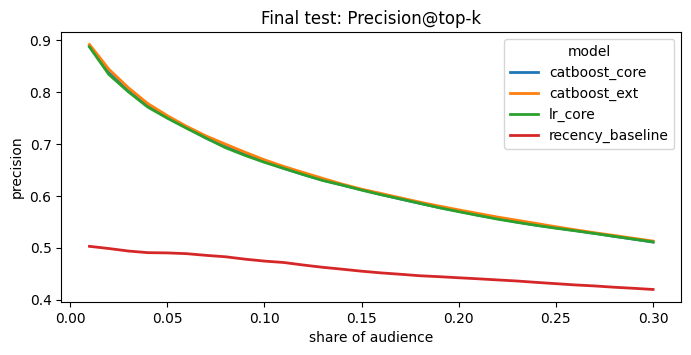

In [8]:
curves = pd.read_csv(RUN / "test_budget_curves.csv")
ax = curves.pivot(index="budget", columns="model", values="precision").plot(figsize=(8, 3.5), linewidth=2, title="Final test: Precision@top-k")
ax.set_xlabel("share of audience"); ax.set_ylabel("precision")

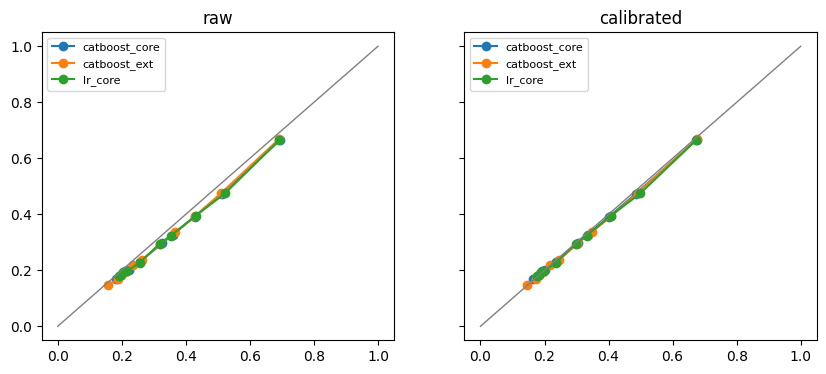

In [9]:
rel = pd.read_csv(RUN / "test_reliability_bins.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, kind in zip(axes, ["raw", "calibrated"]):
    for m, g in rel[rel.kind == kind].groupby("model"):
        ax.plot(g.mean_pred, g.frac_pos, marker="o", label=m)
    ax.plot([0, 1], [0, 1], color="grey", linewidth=1); ax.set_title(kind); ax.legend(fontsize=8)

## Batch scoring

In [10]:
pd.DataFrame([read(p) for p in sorted((RUN / "scoring").glob("*.json"))])[["as_of_date", "model_version", "n_scored", "k", "primary_probability_field", "calibration_fallback_used", "label_window_observed"]]

,as_of_date,model_version,n_scored,k,primary_probability_field,calibration_fallback_used,label_window_observed
0,2020-08-24,full-20261031T151306Z-b6b9e1/catboost_core,539884,26995,calibrated_probability,False,True
1,2020-09-23,full-20261031T151306Z-b6b9e1/catboost_core,518920,25946,calibrated_probability,False,False
